<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/quantum_field_theory/qft_ch05_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Quantum Field Theory* — `qft_ch05_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# QFT Ch 5 Figures — Colab Notebook
**Quantum Field Theory · Chapter 5: Quantum Electrodynamics**

PSE Lab · SeoulTech · Tong (Cambridge)

| Figure | Topic | Slide |
|--------|-------|-------|
| fig01 | Maxwell field, gauge fixing, photon polarisations | §5.1–5.2 |
| fig02 | QED Feynman rules, vertex diagram, running $\alpha$ | §5.3 |
| fig03 | $e^+e^-\to\mu^+\mu^-$, angular dist., Compton Klein-Nishina | §5.4 |
| fig04 | Ward identity, vacuum polarisation, anomalous $g-2$ | §5.5–5.6 |

---
## fig01 · Maxwell Field & Gauge Symmetry (§5.1–5.2)

**Left**: Planck distribution vs Rayleigh-Jeans — quantization resolves the UV catastrophe. **Centre**: Gauge symmetry $A_\mu\to A_\mu+\partial_\mu\alpha$, gauge fixing, physical DOF=2. **Right**: Two transverse polarisation vectors; longitudinal mode is unphysical.

  saved -> figures/ch05/fig01_maxwell.png


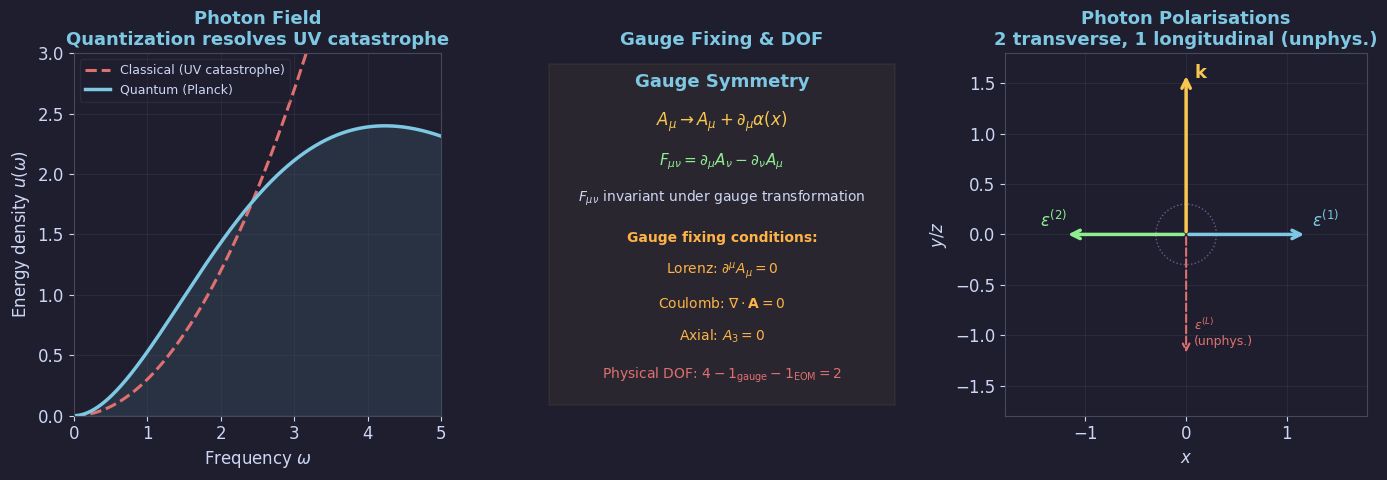

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch05'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig01: Maxwell field + gauge fixing + photon polarisations ────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: EM field energy density vs frequency (Planck-like, schematic)
ax = axes[0]
omega = np.linspace(0.01, 5, 400)
# Classical: Rayleigh-Jeans ~ omega^2
rj = 0.3 * omega**2
# Quantum (Planck): photons
T = 1.5
planck = omega**3 / (np.exp(omega/T) - 1) * 0.5
ax.plot(omega, rj,     color=RED,   lw=2.2, ls='--', label=r'Classical (UV catastrophe)')
ax.plot(omega, planck, color=BLUE,  lw=2.5, label=r'Quantum (Planck)')
ax.fill_between(omega, planck, color=BLUE, alpha=0.12)
ax.set_xlabel(r'Frequency $\omega$')
ax.set_ylabel(r'Energy density $u(\omega)$')
ax.set_title('Photon Field\n' + r'Quantization resolves UV catastrophe', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(0, 5); ax.set_ylim(0, 3)

# Centre: gauge freedom — A_mu gauge orbits (schematic)
ax2 = axes[1]
ax2.axis('off')
items = [
    (0.50, 0.92, 'Gauge Symmetry',                                         BLUE,   13, 'bold'),
    (0.50, 0.81, r'$A_\mu \to A_\mu + \partial_\mu\alpha(x)$',            YELLOW, 12, 'normal'),
    (0.50, 0.70, r'$F_{\mu\nu}=\partial_\mu A_\nu-\partial_\nu A_\mu$',   GREEN,  11, 'normal'),
    (0.50, 0.60, r'$F_{\mu\nu}$ invariant under gauge transformation',    FG,     10, 'normal'),
    (0.50, 0.49, 'Gauge fixing conditions:',                               ORANGE, 10, 'bold'),
    (0.50, 0.40, r'Lorenz: $\partial^\mu A_\mu=0$',                       ORANGE, 10, 'normal'),
    (0.50, 0.31, r'Coulomb: $\nabla\cdot\mathbf{A}=0$',                   ORANGE, 10, 'normal'),
    (0.50, 0.22, r'Axial: $A_3=0$',                                       ORANGE, 10, 'normal'),
    (0.50, 0.11, r'Physical DOF: $4-1_{\rm gauge}-1_{\rm EOM}=2$',        RED,    10, 'normal'),
]
for (xp, yp, txt, col, fs, fw) in items:
    ax2.text(xp, yp, txt, ha='center', va='center', color=col,
             fontsize=fs, fontweight=fw, transform=ax2.transAxes)
rect = plt.Rectangle((0.03, 0.03), 0.94, 0.94, fill=True,
                      facecolor=YELLOW, alpha=0.05,
                      edgecolor=YELLOW, lw=1.5, transform=ax2.transAxes)
ax2.add_patch(rect)
ax2.set_title('Gauge Fixing & DOF', color=BLUE)

# Right: photon polarisation vectors (transverse modes)
ax3 = axes[2]
ax3.set_aspect('equal')
theta = np.linspace(0, 2*np.pi, 200)
# Momentum direction: z-axis
ax3.annotate('', xy=(0, 1.6), xytext=(0, 0),
             arrowprops=dict(arrowstyle='->', color=YELLOW, lw=2.5, mutation_scale=15))
ax3.text(0.08, 1.55, r'$\mathbf{k}$', color=YELLOW, fontsize=13)
# Polarisation 1: x-direction
ax3.annotate('', xy=(1.2, 0), xytext=(0, 0),
             arrowprops=dict(arrowstyle='->', color=BLUE, lw=2.5, mutation_scale=15))
ax3.text(1.25, 0.08, r'$\epsilon^{(1)}$', color=BLUE, fontsize=12)
# Polarisation 2: y-direction
ax3.annotate('', xy=(0, 0), xytext=(-1.2, 0),
             arrowprops=dict(arrowstyle='<-', color=GREEN, lw=2.5, mutation_scale=15))
ax3.text(-1.45, 0.08, r'$\epsilon^{(2)}$', color=GREEN, fontsize=12)
# Longitudinal (unphysical)
ax3.annotate('', xy=(0, -1.2), xytext=(0, 0),
             arrowprops=dict(arrowstyle='->', color=RED, lw=1.5, mutation_scale=12,
                             linestyle='dashed'))
ax3.text(0.08, -1.1, r'$\epsilon^{(L)}$'+'\n(unphys.)', color=RED, fontsize=9)
ax3.plot(np.cos(theta)*0.3, np.sin(theta)*0.3,
         color=PURPLE, lw=1.0, ls=':', alpha=0.5)
ax3.set_xlim(-1.8, 1.8); ax3.set_ylim(-1.8, 1.8)
ax3.set_xlabel('$x$'); ax3.set_ylabel('$y$/$z$')
ax3.set_title('Photon Polarisations\n2 transverse, 1 longitudinal (unphys.)', color=BLUE)
ax3.grid(True)

plt.tight_layout(pad=1.2)
save('fig01_maxwell.png', fig)


---
## fig02 · QED Feynman Rules (§5.3)

**Left**: QED Feynman rules — fermion propagator, photon propagator, vertex $-ie\gamma^\mu$. **Centre**: QED vertex diagram $e^-\gamma\to e^-$. **Right**: Running of $\alpha(\mu)$ — $\alpha(0)=1/137$, $\alpha(M_Z)\approx1/128$.

  saved -> figures/ch05/fig02_qed_rules.png


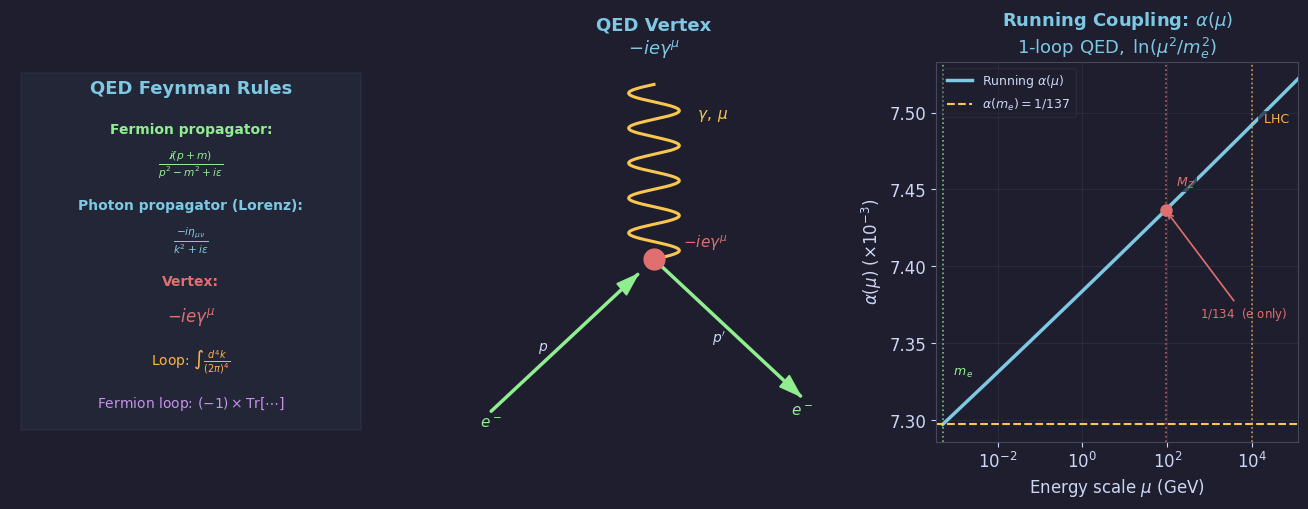

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter
from matplotlib.transforms import blended_transform_factory
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch05'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', pad_inches=0.02, facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# ── Left: QED Feynman rules text panel ────────────────────────────────────
ax = axes[0]
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')
for (xp,yp,txt,col,fs,fw) in [
    (0.50, 0.93, 'QED Feynman Rules',                               BLUE,   13, 'bold'),
    (0.50, 0.82, 'Fermion propagator:',                              GREEN,  10, 'bold'),
    (0.50, 0.73, r'$\frac{i(\not{p}+m)}{p^2-m^2+i\varepsilon}$',   GREEN,  11, 'normal'),
    (0.50, 0.62, 'Photon propagator (Lorenz):',                     BLUE,   10, 'bold'),
    (0.50, 0.53, r'$\frac{-i\eta_{\mu\nu}}{k^2+i\varepsilon}$',    BLUE,   11, 'normal'),
    (0.50, 0.42, 'Vertex:',                                          RED,    10, 'bold'),
    (0.50, 0.33, r'$-ie\gamma^\mu$',                                RED,    12, 'normal'),
    (0.50, 0.21, r'Loop: $\int\frac{d^4k}{(2\pi)^4}$',             ORANGE, 10, 'normal'),
    (0.50, 0.10, r'Fermion loop: $(-1)\times\mathrm{Tr}[\cdots]$', PURPLE, 10, 'normal'),
]:
    ax.text(xp, yp, txt, ha='center', va='center',
            color=col, fontsize=fs, fontweight=fw)
ax.add_patch(plt.Rectangle((0.03,0.03),0.94,0.94,
             fill=True, facecolor=BLUE, alpha=0.05, edgecolor=BLUE, lw=1.5))
#ax.set_title('QED Feynman Rules', color=BLUE)

# ── Centre: QED vertex diagram ─────────────────────────────────────────────

ax2 = axes[1]
ax2.set_xlim(0,1); ax2.set_ylim(0,1); ax2.axis('off')
cx, cy = 0.50, 0.48

def draw_arrow(ax, x0, y0, x1, y1, col, lw=2.5):
    dx=x1-x0; dy=y1-y0; L=np.sqrt(dx**2+dy**2)
    ux, uy = dx/L, dy/L; hl=0.06
    ax.plot([x0, x1-hl*ux], [y0, y1-hl*uy], color=col, lw=lw,
            solid_capstyle='round')
    ax.add_patch(mpatches.FancyArrow(
        x1-hl*ux, y1-hl*uy, hl*ux*0.01, hl*uy*0.01,
        width=0, head_width=0.04, head_length=hl,
        fc=col, ec=col, length_includes_head=True))

# incoming e-: bottom-left → vertex
draw_arrow(ax2, 0.05, 0.08, cx, cy, GREEN)
ax2.text(0.02, 0.03, r'$e^-$', color=GREEN, fontsize=11, va='bottom')
ax2.text(0.18, 0.24, r'$p$',   color=FG,    fontsize=10)
# outgoing e-: vertex → bottom-right
draw_arrow(ax2, cx, cy, 0.95, 0.08, GREEN)
ax2.text(0.88, 0.06, r"$e^-$", color=GREEN, fontsize=11, va='bottom')
ax2.text(0.66, 0.26, r"$p'$",  color=FG,    fontsize=10)
# photon: vertex → top-center (wavy line)
t = np.linspace(0, 1, 300)
ax2.plot(cx + 0.07*np.sin(t*10*np.pi),
         cy + (0.94-cy)*t, color=YELLOW, lw=2.2)
ax2.text(cx+0.12, 0.88, r'$\gamma,\;\mu$', color=YELLOW, fontsize=11, va='top')
# vertex dot + label
ax2.plot([cx], [cy], 'o', color=RED, ms=15, zorder=5)
ax2.text(cx+0.08, cy+0.03, r'$-ie\gamma^\mu$', color=RED, fontsize=11)
ax2.set_title('QED Vertex\n' + r'$-ie\gamma^\mu$', color=BLUE)

# ── Right: running alpha ───────────────────────────────────────────────────
ax3 = axes[2]

m_e = 0.511e-3   # GeV
alpha0 = 1/137.036
mu = np.logspace(np.log10(m_e), np.log10(1.2e5), 500)
alpha_run = alpha0 / (1 - (alpha0/(3*np.pi)) * 2*np.log(mu/m_e))
alpha_run = np.where(alpha_run > 0.05, np.nan, alpha_run)  # Landau pole 제거

ax3.plot(mu, alpha_run, color=BLUE, lw=2.5, label=r'Running $\alpha(\mu)$')
ax3.axhline(alpha0, color=YELLOW, lw=1.5, ls='--', label=r'$\alpha(m_e)=1/137$')

trans = blended_transform_factory(ax3.transData, ax3.transAxes)
for (mu_v, lab, col, ly) in [
        (m_e,  r'$m_e$', GREEN,  0.18),   # y=18% 높이
        (91.2, r'$M_Z$', RED,    0.68),   # y=68% 높이
        (1e4,  r'LHC',   ORANGE, 0.85)]:  # y=85% 높이
    ax3.axvline(mu_v, color=col, lw=1.2, ls=':', alpha=0.8)
    ax3.text(mu_v * 1.5, ly, f' {lab}', transform=trans,
             color=col, fontsize=9, ha='left', va='center',
             bbox=dict(facecolor=BG, alpha=0.7, edgecolor='none', pad=1))

alpha_MZ = alpha0 / (1 - (alpha0/(3*np.pi)) * 2*np.log(91.2/m_e))
ax3.plot([91.2], [alpha_MZ], 'o', color=RED, ms=8, zorder=5)
ax3.annotate(f'$1/{1/alpha_MZ:.0f}$  (e only)',
             xy=(91.2, alpha_MZ), xytext=(600, alpha_MZ - 0.00007),
             color=RED, fontsize=8.5,
             arrowprops=dict(arrowstyle='->', color=RED, lw=1.2))

ax3.set_xscale('log')
ax3.set_xlabel(r'Energy scale $\mu$ (GeV)')
ax3.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y*1e3:.2f}'))
ax3.set_ylabel(r'$\alpha(\mu)$ $(\times 10^{-3})$')
ax3.set_title(r'Running Coupling: $\alpha(\mu)$' + '\n' +
              r'$1\text{-loop QED},\; \ln(\mu^2/m_e^2)$', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG)
ax3.grid(True)
ax3.set_xlim(m_e*0.7, 1.2e5)

fig.subplots_adjust(left=0.05, right=0.97, top=0.88, bottom=0.12, wspace=0.28)
save('fig02_qed_rules.png', fig)

---
## fig03 · Tree-Level Processes (§5.4)

**Left**: $e^+e^-\to\mu^+\mu^-$ total cross section — $\sigma\propto1/s$, threshold at $2m_\mu$. **Centre**: Angular distribution $d\sigma/d\Omega\propto1+\cos^2\theta$ and forward-backward asymmetry. **Right**: Compton scattering Klein-Nishina — forward peaked at high energy.

  saved -> figures/ch05/fig03_processes.png


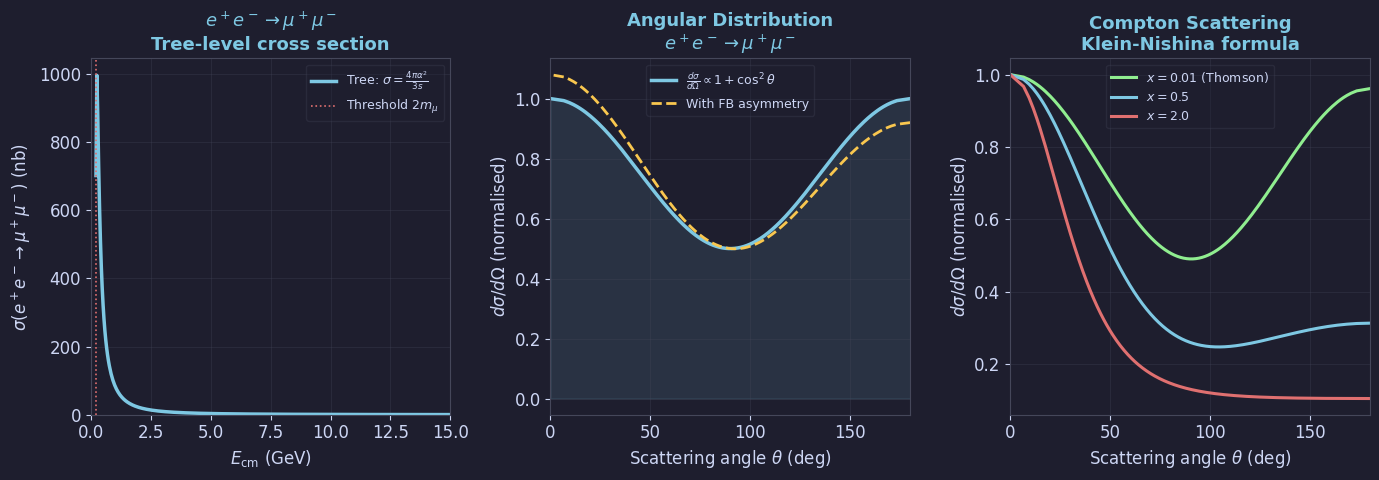

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch05'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig03: e+e- -> mu+mu- cross section + Compton scattering ─────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: e+e- -> mu+mu- sigma vs E_cm
ax = axes[0]
E_cm = np.linspace(0.22, 15, 400)
s = E_cm**2
m_mu = 0.106  # GeV
alpha_val = 1/137.036
# Tree-level: sigma = 4*pi*alpha^2/(3*s) * beta * (1 + 1/(2*beta^2)*(3-beta^4))... simplify
# sigma_pt = 4*pi*alpha^2/(3s), times phase space
beta2 = np.maximum(0, 1 - 4*m_mu**2/s)
beta  = np.sqrt(beta2)
sigma_tree = (4*np.pi*alpha_val**2)/(3*s) * beta * (1 + 0.5*(1-beta2)) * 0.3894e6  # nb
sigma_tree = np.where(beta <= 0, np.nan, sigma_tree)
ax.plot(E_cm, sigma_tree, color=BLUE, lw=2.5,
        label=r'Tree: $\sigma=\frac{4\pi\alpha^2}{3s}$')
# Z-pole enhancement (schematic)
M_Z = 91.2; Gamma_Z = 2.5
sigma_z = sigma_tree * (1 + 15*Gamma_Z**2/((E_cm - M_Z)**2 + Gamma_Z**2/4))
ax.axvline(2*m_mu, color=RED, lw=1.2, ls=':', label=r'Threshold $2m_\mu$')
ax.set_xlabel(r'$E_{\rm cm}$ (GeV)')
ax.set_ylabel(r'$\sigma(e^+e^-\to\mu^+\mu^-)$ (nb)')
ax.set_title(r'$e^+e^-\to\mu^+\mu^-$' + '\nTree-level cross section', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(0, 15); ax.set_ylim(0, None)

# Centre: angular distribution dsigma/dOmega
ax2 = axes[1]
cos_th = np.linspace(-1, 1, 300)
theta_deg = np.degrees(np.arccos(cos_th))
# e+e- -> mu+mu-: (1 + cos^2(theta)) distribution
dsigma = 1 + cos_th**2
dsigma_norm = dsigma / dsigma.max()
ax2.plot(theta_deg, dsigma_norm, color=BLUE, lw=2.5,
         label=r'$\frac{d\sigma}{d\Omega}\propto 1+\cos^2\theta$')
ax2.fill_between(theta_deg, dsigma_norm, color=BLUE, alpha=0.12)
# Forward-backward asymmetry (loop correction, schematic)
dsigma_asym = dsigma_norm * (1 + 0.08*cos_th)
ax2.plot(theta_deg, dsigma_asym, color=YELLOW, lw=2.0, ls='--',
         label=r'With FB asymmetry')
ax2.set_xlabel(r'Scattering angle $\theta$ (deg)')
ax2.set_ylabel(r'$d\sigma/d\Omega$ (normalised)')
ax2.set_title(r'Angular Distribution' + '\n' + r'$e^+e^-\to\mu^+\mu^-$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0, 180)

# Right: Compton scattering — Klein-Nishina formula
ax3 = axes[2]
cos_th2 = np.linspace(-1, 1, 300)
theta2  = np.arccos(cos_th2)
# Klein-Nishina (unpolarised, low energy limit ~ Thomson)
# dsigma/dOmega = (r_e^2/2)(omega'/omega)^2 (omega'/omega + omega/omega' - sin^2 theta)
for x_val, col, lab in [(0.01, GREEN, r'$x=0.01$ (Thomson)'),
                         (0.5,  BLUE,  r'$x=0.5$'),
                         (2.0,  RED,   r'$x=2.0$')]:
    omega_ratio = 1.0 / (1 + x_val*(1 - cos_th2))
    kn = 0.5 * omega_ratio**2 * (omega_ratio + 1/omega_ratio - np.sin(theta2)**2)
    kn /= kn.max()
    ax3.plot(np.degrees(theta2), kn, color=col, lw=2.2, label=lab)
ax3.set_xlabel(r'Scattering angle $\theta$ (deg)')
ax3.set_ylabel(r'$d\sigma/d\Omega$ (normalised)')
ax3.set_title('Compton Scattering\nKlein-Nishina formula', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(0, 180)

plt.tight_layout(pad=1.2)
save('fig03_processes.png', fig)


---
## fig04 · Ward Identity, Vacuum Polarisation & $g-2$ (§5.5–5.6)

**Left**: Ward identity $k_\mu\mathcal{M}^\mu=0$ — gauge invariance, photon masslessness. **Centre**: Vacuum polarisation $\Pi(q^2)$ — real and imaginary parts, threshold at $q^2=4m_e^2$. **Right**: Anomalous magnetic moment $a_e=(g-2)/2=\alpha/(2\pi)+\cdots$ — most precise QFT prediction.

  saved -> figures/ch05/fig04_ward_g2.png


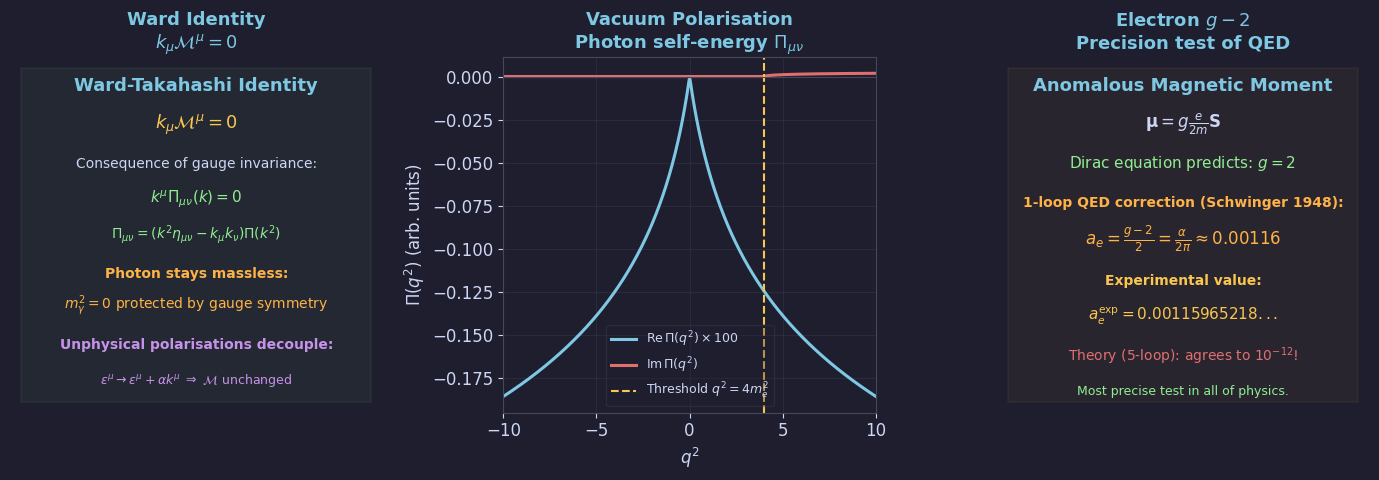

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'
plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})
OUTDIR = 'figures/ch05'; os.makedirs(OUTDIR, exist_ok=True)
def save(name, fig=None):
    f = fig or plt.gcf(); path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}'); plt.show()

# ── fig04: Ward identity + vacuum polarisation + anomalous magnetic moment
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Left: Ward identity (text panel)
ax = axes[0]
ax.axis('off')
items = [
    (0.50, 0.92, 'Ward-Takahashi Identity',                                BLUE,   13, 'bold'),
    (0.50, 0.81, r'$k_\mu \mathcal{M}^\mu = 0$',                          YELLOW, 13, 'normal'),
    (0.50, 0.70, 'Consequence of gauge invariance:',                       FG,     10, 'normal'),
    (0.50, 0.60, r'$k^\mu \Pi_{\mu\nu}(k)=0$',                            GREEN,  11, 'normal'),
    (0.50, 0.50, r'$\Pi_{\mu\nu}=(k^2\eta_{\mu\nu}-k_\mu k_\nu)\Pi(k^2)$', GREEN, 10, 'normal'),
    (0.50, 0.39, 'Photon stays massless:',                                 ORANGE, 10, 'bold'),
    (0.50, 0.30, r'$m_\gamma^2=0$ protected by gauge symmetry',            ORANGE, 10, 'normal'),
    (0.50, 0.19, 'Unphysical polarisations decouple:',                     PURPLE, 10, 'bold'),
    (0.50, 0.09, r'$\epsilon^\mu\to\epsilon^\mu+\alpha k^\mu$ $\Rightarrow$ $\mathcal{M}$ unchanged',
                                                                            PURPLE, 9, 'normal'),
]
for (xp, yp, txt, col, fs, fw) in items:
    ax.text(xp, yp, txt, ha='center', va='center', color=col,
            fontsize=fs, fontweight=fw, transform=ax.transAxes)
rect = plt.Rectangle((0.03, 0.03), 0.94, 0.94, fill=True,
                      facecolor=GREEN, alpha=0.05,
                      edgecolor=GREEN, lw=1.5, transform=ax.transAxes)
ax.add_patch(rect)
ax.set_title('Ward Identity\n' + r'$k_\mu\mathcal{M}^\mu=0$', color=BLUE)

# Centre: vacuum polarisation Pi(q^2) — photon self-energy
ax2 = axes[1]
q2 = np.linspace(-10, 10, 500)
m_e = 1.0
alpha_v = 1/137.0
# Real part of Pi(q^2) schematic (Kallen-Lehmann)
# For q^2 < 4m^2: real; for q^2 > 4m^2: complex (absorptive part)
Pi_real = np.where(q2 < 0,
                   -alpha_v/(3*np.pi) * np.log(np.abs(q2)/m_e**2 + 1),
                   -alpha_v/(3*np.pi) * np.log(np.abs(q2)/m_e**2 + 1))
Pi_imag = np.where(q2 > 4*m_e**2,
                   alpha_v/3 * np.sqrt(1 - 4*m_e**2/np.maximum(q2, 4.01)),
                   0.0)
ax2.plot(q2, Pi_real * 100, color=BLUE, lw=2.2, label=r'$\mathrm{Re}\,\Pi(q^2)\times100$')
ax2.plot(q2, Pi_imag,       color=RED,  lw=2.2, label=r'$\mathrm{Im}\,\Pi(q^2)$')
ax2.axvline(4*m_e**2, color=YELLOW, lw=1.5, ls='--', label=r'Threshold $q^2=4m_e^2$')
ax2.axhline(0, color=EDGE, lw=0.8)
ax2.set_xlabel(r'$q^2$')
ax2.set_ylabel(r'$\Pi(q^2)$ (arb. units)')
ax2.set_title('Vacuum Polarisation\n' + r'Photon self-energy $\Pi_{\mu\nu}$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(-10, 10)

# Right: anomalous magnetic moment (g-2)
ax3 = axes[2]
ax3.axis('off')
items3 = [
    (0.50, 0.92, 'Anomalous Magnetic Moment',                              BLUE,   13, 'bold'),
    (0.50, 0.81, r'$\mathbf{\mu}=g\frac{e}{2m}\mathbf{S}$',              FG,     12, 'normal'),
    (0.50, 0.70, 'Dirac equation predicts: $g=2$',                        GREEN,  11, 'normal'),
    (0.50, 0.59, r'1-loop QED correction (Schwinger 1948):',              ORANGE, 10, 'bold'),
    (0.50, 0.49, r'$a_e=\frac{g-2}{2}=\frac{\alpha}{2\pi}\approx0.00116$', ORANGE, 12, 'normal'),
    (0.50, 0.37, 'Experimental value:',                                    YELLOW, 10, 'bold'),
    (0.50, 0.27, r'$a_e^{\rm exp}=0.00115965218...$',                     YELLOW, 11, 'normal'),
    (0.50, 0.16, r'Theory (5-loop): agrees to $10^{-12}$!',               RED,    10, 'normal'),
    (0.50, 0.06, 'Most precise test in all of physics.',                   GREEN,   9, 'normal'),
]
for (xp, yp, txt, col, fs, fw) in items3:
    ax3.text(xp, yp, txt, ha='center', va='center', color=col,
             fontsize=fs, fontweight=fw, transform=ax3.transAxes)
rect3 = plt.Rectangle((0.03, 0.03), 0.94, 0.94, fill=True,
                       facecolor=ORANGE, alpha=0.05,
                       edgecolor=ORANGE, lw=1.5, transform=ax3.transAxes)
ax3.add_patch(rect3)
ax3.set_title('Electron $g-2$\nPrecision test of QED', color=BLUE)

plt.tight_layout(pad=1.2)
save('fig04_ward_g2.png', fig)


---
## Download All Figures

In [5]:
import os, zipfile
from google.colab import files

# AUTO-INJECTED: Korean font setup for matplotlib
import os as _os
import matplotlib.font_manager as _fm
import matplotlib.pyplot as _plt
if not any('NanumGothic' in f.name for f in _fm.fontManager.ttflist):
    for _font in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
                  '/usr/share/fonts/truetype/nanum/NanumGothicBold.ttf']:
        if _os.path.exists(_font):
            _fm.fontManager.addfont(_font)
_plt.rcParams.update({'font.family': 'NanumGothic', 'axes.unicode_minus': False})
del _os, _fm, _plt
# END AUTO-INJECTED Korean font setup


OUTDIR = 'figures/ch05'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')])
print(f'Found {len(saved)} figures:')
for f in saved:
    print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')
zip_name = 'qft_ch05_figures.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 4 figures:
  fig01_maxwell.png  (167 KB)
  fig02_qed_rules.png  (161 KB)
  fig03_processes.png  (199 KB)
  fig04_ward_g2.png  (210 KB)
Zip: qft_ch05_figures.zip  (700 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>